# 00: Data-Quality Audit

**Goal:** find every data-quality issue in the Olist data *before* analysis, and record for each one its **size**, the **decision** (FIX / FLAG / KEEP / SCOPE) and the **action taken**.

- The checks live in `sql/04_data_quality_checks.sql`, one block per issue, with the decision written next to the query that measures it.
- `src/data_quality.py` runs them; this notebook only calls those functions and shows the results.
- The written summary is `docs/DATA_QUALITY_REPORT.md`.

| Decision | Meaning |
|---|---|
| **FIX** | corrected in `sql/01_staging.sql` |
| **FLAG** | kept, labelled in `fact_orders.dq_flags` or excluded by a stated filter |
| **KEEP** | genuine business behaviour, no change |
| **SCOPE** | deliberately out of scope |

Prerequisite: `python scripts/build_db.py` has built `data/olist.duckdb`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data_quality import missing_profile, run_audit
from src.db import connect

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
con = connect(read_only=True)

BLUE, MUTED, INK, INK2 = "#2a78d6", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "font.size": 10,
    }
)
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Missing values in the raw tables

Raw columns are loaded as text, so a NULL here means the value was genuinely empty in the CSV.

In [2]:
missing = missing_profile(con, schema="raw")
missing

,table,column,nulls,rows,pct
0,order_reviews,review_comment_title,87656,99224,88.34
1,order_reviews,review_comment_message,58247,99224,58.70
2,orders,order_delivered_customer_date,2965,99441,2.98
3,products,product_name_lenght,610,32951,1.85
4,products,product_category_name,610,32951,1.85
5,products,product_description_lenght,610,32951,1.85
6,products,product_photos_qty,610,32951,1.85
7,orders,order_delivered_carrier_date,1783,99441,1.79
8,orders,order_approved_at,160,99441,0.16
9,products,product_weight_g,2,32951,0.01


**Reading it:** the review title and message are mostly empty (customers often leave only a star score). Missing order dates line up with order status (checked in section 2). Products with no category also lack name length, description length and photo count: the same 610 rows.

In [3]:
# Confirm the 610 products missing a category are the same rows missing the other descriptive fields
con.execute("""
    SELECT COUNT(*) AS products_missing_category,
           COUNT(*) FILTER (WHERE product_name_lenght IS NULL
                             AND product_description_lenght IS NULL
                             AND product_photos_qty IS NULL) AS also_missing_other_3_fields
    FROM raw.products WHERE product_category_name IS NULL
""").df()

,products_missing_category,also_missing_other_3_fields
0,610,610


## 2. The audit table: every issue, its size and the decision

In [4]:
audit = run_audit(con)
audit.to_csv(ROOT / "sql" / "results" / "data_quality_audit.csv", index=False)
print(f"{len(audit)} checks run")
audit

45 checks run


,check,table,issue,affected,base,pct,decision,action
0,orders_not_delivered,orders,"Orders not in status 'delivered' (shipped, canceled, unavailable, invoiced, processing, created, approved)",2963,99441,2.98,KEEP,"Kept in fact_orders; delivery metrics use is_delivered only, revenue = delivered orders only."
1,orders_missing_approved_ts,orders,"Missing approval timestamp (141 canceled, 5 created, 14 delivered)",160,99441,0.16,FLAG,Kept as NULL; approval_hours is NULL for these orders and excluded from approval-time averages.
2,orders_missing_delivery_ts,orders,Missing customer delivery date (mostly shipped / canceled / unavailable orders),2965,99441,2.98,KEEP,Expected for undelivered orders; is_late and delivery_days are NULL unless is_delivered.
3,orders_delivered_without_date,orders,Status 'delivered' but no customer delivery date,8,96478,0.01,FLAG,"dq_flags 'delivered_without_date'; treated as not delivered (is_delivered = false), so excluded from is_late."
4,orders_date_without_delivered_status,orders,Canceled orders that nevertheless have a customer delivery date,6,96476,0.01,FLAG,"dq_flags 'date_without_delivered_status'; status wins, so not counted as delivered."
5,orders_carrier_before_purchase,orders,Carrier pickup timestamp earlier than purchase timestamp (impossible sequence),166,97658,0.17,FLAG,dq_flags 'carrier_before_purchase'; carrier date not used as an ML feature (post-purchase anyway).
6,orders_customer_before_carrier,orders,Delivered to customer before carrier pickup (impossible sequence),23,96475,0.02,FLAG,"dq_flags 'customer_before_carrier'; kept for is_late (customer date is the target), excluded in sensitivity checks."
7,orders_approved_before_purchase,orders,"Approval earlier than purchase (checked, impossible sequence)",0,99281,0.00,KEEP,None found; check retained so a future data refresh would surface it.
8,orders_delivered_before_purchase,orders,"Customer delivery earlier than purchase (checked, impossible sequence)",0,96476,0.00,KEEP,None found; check retained.
9,orders_without_items,orders,Orders with no rows in order_items (767 of them canceled or unavailable),775,99441,0.78,FLAG,dq_flags 'no_items'; kept in fact_orders via LEFT JOIN; order_value is NULL.


In [5]:
# How many issues per decision, and per table
summary = audit.pivot_table(
    index="table", columns="decision", values="check", aggfunc="count", fill_value=0
)
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

decision,FIX,FLAG,KEEP,SCOPE,total
table,,,,,
orders,0,10,6,0,16
order_reviews,4,1,3,0,8
products,3,2,0,0,5
customers,2,1,1,0,4
order_items,0,0,4,0,4
order_payments,0,2,1,1,4
geolocation,3,0,0,0,3
sellers,0,1,0,0,1


### Missing order dates are explained by order status

A missing delivery date is a problem only for orders that claim to be delivered.

In [6]:
con.execute("""
    SELECT order_status,
           COUNT(*)                                             AS orders,
           COUNT(*) FILTER (WHERE approved_ts IS NULL)           AS no_approval,
           COUNT(*) FILTER (WHERE delivered_carrier_ts IS NULL)  AS no_carrier_date,
           COUNT(*) FILTER (WHERE delivered_customer_ts IS NULL) AS no_delivery_date
    FROM stg_orders
    GROUP BY order_status
    ORDER BY orders DESC
""").df()

,order_status,orders,no_approval,no_carrier_date,no_delivery_date
0,delivered,96478,14,2,8
1,shipped,1107,0,0,1107
2,canceled,625,141,550,619
3,unavailable,609,0,609,609
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,created,5,5,5,5
7,approved,2,0,2,2


## 3. Time coverage: which months are usable?

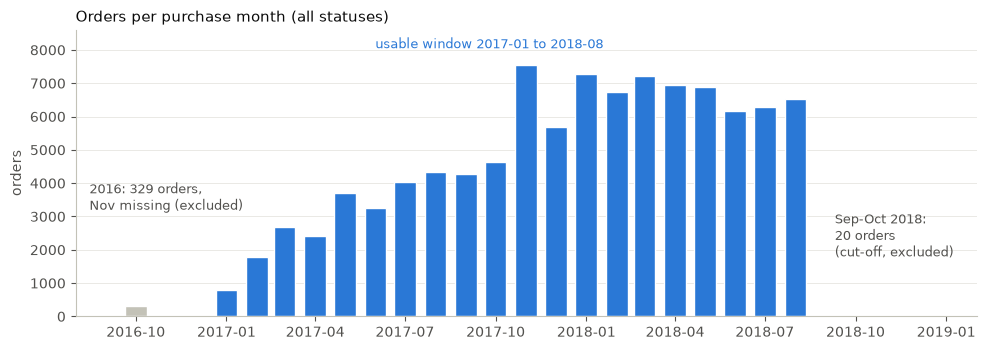

     month  orders  usable
2016-09-01       4   False
2016-10-01     324   False
2016-12-01       1   False
2018-09-01      16   False
2018-10-01       4   False


In [7]:
monthly = con.execute("""
    SELECT DATE_TRUNC('month', purchase_ts)::DATE AS month, COUNT(*) AS orders
    FROM stg_orders GROUP BY 1 ORDER BY 1
""").df()
monthly["usable"] = monthly["month"].between(pd.Timestamp("2017-01-01"), pd.Timestamp("2018-08-01"))

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [BLUE if u else MUTED for u in monthly["usable"]]
ax.bar(monthly["month"], monthly["orders"], width=22, color=colors, edgecolor="white", linewidth=1)
ax.set_title("Orders per purchase month (all statuses)", loc="left", color=INK, fontsize=11)
ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
ax.annotate(
    "2016: 329 orders,\nNov missing (excluded)",
    xy=(pd.Timestamp("2016-10-01"), 400),
    xytext=(pd.Timestamp("2016-08-15"), 3200),
    color=INK2,
    fontsize=9,
)
ax.annotate(
    "Sep-Oct 2018:\n20 orders\n(cut-off, excluded)",
    xy=(pd.Timestamp("2018-09-01"), 100),
    xytext=(pd.Timestamp("2018-09-10"), 1800),
    color=INK2,
    fontsize=9,
)
ax.set_xlim(pd.Timestamp("2016-08-01"), pd.Timestamp("2019-02-01"))
ax.set_ylim(0, 8600)
ax.text(
    pd.Timestamp("2017-06-01"), 8050, "usable window 2017-01 to 2018-08", color=BLUE, fontsize=9
)
plt.tight_layout()
fig.savefig(FIG_DIR / "dq_orders_per_month.png", dpi=150)
plt.show()
print(monthly.loc[~monthly["usable"]].to_string(index=False))

## 4. Size of each non-trivial issue

Checks with 0 affected rows and the SCOPE / whole-column items are left out, so the chart shows real problems only.

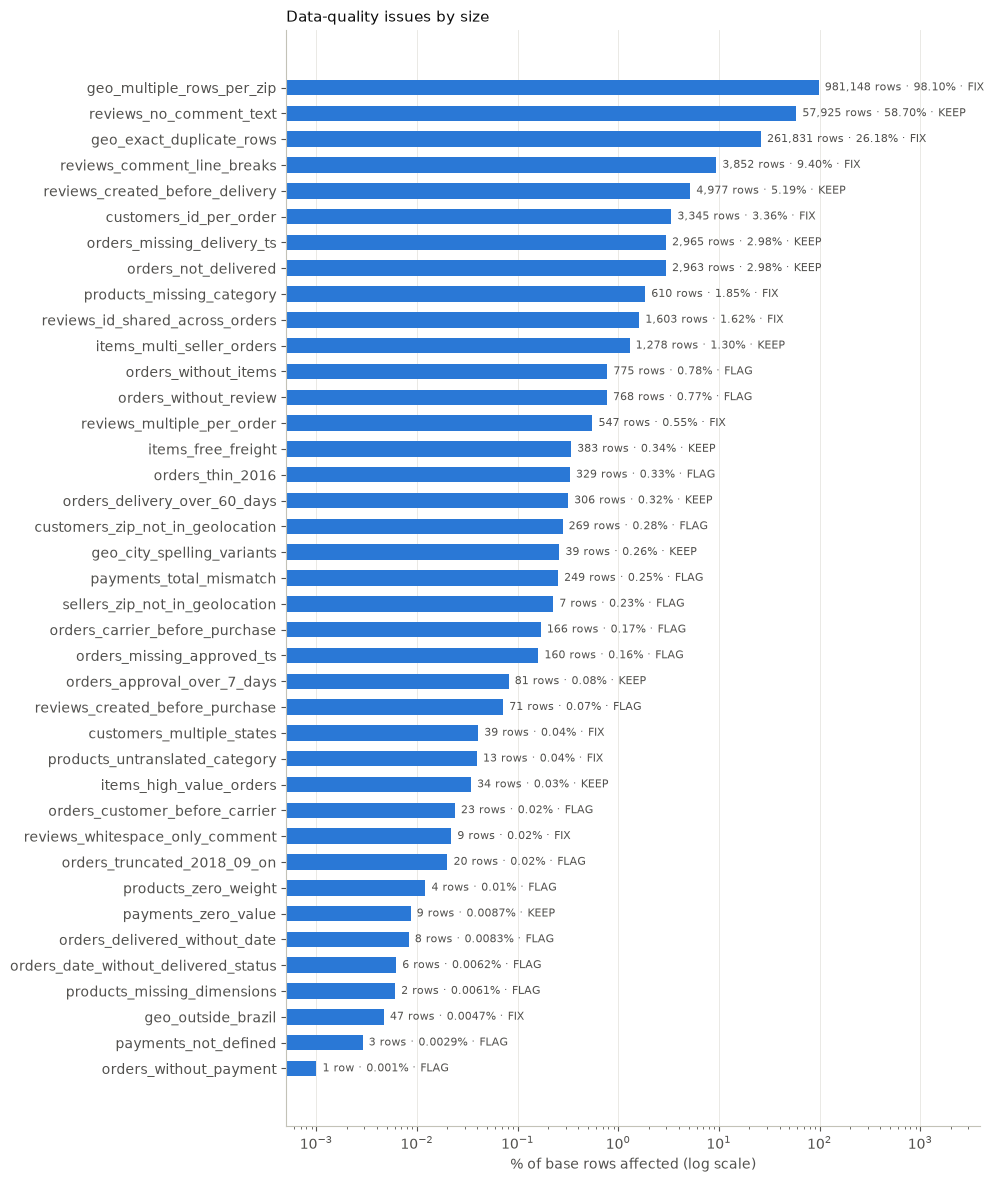

In [8]:
# products_column_typos counts columns, not rows, so it is left off this rows-based chart
plot_df = audit[
    (audit["affected"] > 0)
    & (audit["pct"] < 100)
    & (audit["decision"] != "SCOPE")
    & (audit["check"] != "products_column_typos")
].copy()
plot_df["exact_pct"] = (
    100 * plot_df["affected"] / plot_df["base"]
)  # unrounded, so tiny issues still draw
plot_df = plot_df.sort_values("exact_pct")
fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot_df) + 1))
ax.barh(plot_df["check"], plot_df["exact_pct"], color=BLUE, height=0.6)
ax.set_xscale("log")
ax.set_xlabel("% of base rows affected (log scale)")
ax.set_title("Data-quality issues by size", loc="left", color=INK, fontsize=11)
ax.grid(axis="y", visible=False)
for y, (pct, n, dec) in enumerate(
    zip(plot_df["exact_pct"], plot_df["affected"], plot_df["decision"], strict=True)
):
    label = f"{pct:.2g}%" if pct < 0.01 else f"{pct:.2f}%"
    ax.text(
        pct * 1.15,
        y,
        f"{n:,} row{'' if n == 1 else 's'} · {label} · {dec}",
        va="center",
        fontsize=8,
        color=INK2,
    )
ax.set_xlim(plot_df["exact_pct"].min() / 2, plot_df["exact_pct"].max() * 40)
plt.tight_layout()
fig.savefig(FIG_DIR / "dq_issue_sizes.png", dpi=150)
plt.show()

## 5. Net effect on the analysis table (`fact_orders`)

In [9]:
flags = con.execute("""
    SELECT flag, COUNT(*) AS orders
    FROM (SELECT UNNEST(STRING_SPLIT(dq_flags, ';')) AS flag FROM fact_orders WHERE dq_flags <> '')
    GROUP BY flag ORDER BY orders DESC
""").df()
clean = con.execute(
    "SELECT COUNT(*) FILTER (WHERE dq_flags = ''), COUNT(*) FROM fact_orders"
).fetchone()
print(f"clean orders: {clean[0]:,} of {clean[1]:,} ({100 * clean[0] / clean[1]:.2f}%)")
flags

clean orders: 97,467 of 99,441 (98.01%)


,flag,orders
0,no_items,775
1,no_review,768
2,payment_total_mismatch,249
3,carrier_before_purchase,166
4,customer_before_carrier,23
5,delivered_without_date,8
6,date_without_delivered_status,6
7,no_payment,1


In [10]:
# Sensitivity check: does excluding flagged orders change the headline late rate?
con.execute("""
    SELECT 'all delivered' AS population, COUNT(*) AS delivered,
           ROUND(100.0 * AVG(is_late::INT), 2) AS late_pct
    FROM fact_orders WHERE is_delivered
    UNION ALL
    SELECT 'delivered, no dq_flags', COUNT(*), ROUND(100.0 * AVG(is_late::INT), 2)
    FROM fact_orders WHERE is_delivered AND dq_flags = ''
""").df()

,population,delivered,late_pct
0,all delivered,96470,6.77
1,"delivered, no dq_flags",95392,6.67


## Conclusion

The key numbers, decisions and reasons are written up in **`docs/DATA_QUALITY_REPORT.md`**. The full audit table is saved to `sql/results/data_quality_audit.csv`.

In [11]:
con.close()